# Phase 3 · Rhetorical Role Prediction

<div align="center">

## MODEL2 · Contextual Full Fine-Tuning (regularized + class-balanced candidates)

**Full-model adaptation**

`CS781 Capstone` &nbsp; · &nbsp; `Corporate Law + IT` &nbsp; · &nbsp; `Sentence classification`

</div>

---

### Experiment at a glance

| Item | Configuration |
|:--|:--|
| **Phase 1 backbone** | `model2(3).ipynb` |
| **Architecture** | RoPE, RMSNorm, QK normalization, GQA and a SiLU feed-forward network |
| **Representation size** | 512-dimensional hidden states |
| **Adaptation method** | Full Fine-Tuning |
| **Checkpoint selection** | Development Macro-F1 |
| **Domains** | Corporate Law (CL) and Information Technology (IT) |

> **Objective**
>
> Updates the complete Phase 1 backbone together with the sentence-classification head. The model predicts exactly one rhetorical-role label per sentence while preserving document order.

### Before you run

1. Attach the **matching Phase 1 artifacts** as a Kaggle input dataset.
2. Set `ASSET_DIR` in the setup cell to that dataset's directory.
3. Confirm it contains `pytorch_model.bin` and `custom_bpe_scratch.json`.
4. Enable internet access and add a Kaggle Secret named `HF` containing a Hugging Face read token with access to `Exploration-Lab/CS-781-Capstone`.

> **Checkpoint safety:** Model 2 and Model 4 checkpoints/tokenizers are not interchangeable. This notebook uses the architecture and tokenizer implementation from its matching Phase 1 notebook; it does not use an external pretrained language model.

### Notebook workflow

`Setup` → `Tokenizer` → `Backbone` → `Data` → `Adaptation` → `Training & validation` → `Predictions`

---

**Run cells from top to bottom.** Training has not been executed in this environment, so no performance scores are claimed.


> **Hugging Face access required:** the notebook downloads the Phase-3 JSON files from `Exploration-Lab/CS-781-Capstone` using a token. In Kaggle, add a secret named `HF` with a read token and enable notebook access to secrets. Also attach the matching Phase-1 checkpoint and tokenizer files as a Kaggle Input.


> **Performance target:** 0.50+ official development Macro-F1 is an aspirational target, not a validated result. Previous baseline: full fine-tuning 0.2619; LoRA 0.27. This notebook keeps the Phase-1 checkpoint/architecture but modifies the Phase-3 input construction, classifier and optimization. Train, then compare measured scores. No external labeled data or dev/test-label training is used.


> **Updated performance-oriented version:** The same Phase-1 Model 2 checkpoint/tokenizer is retained; the Phase-3 sequence representation, regularization, and training objectives now intentionally differ from LoRA. Previous controlled comparison results are not directly comparable.


In [3]:
import json, os, random, math
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

ASSET_DIR = Path('/kaggle/input/datasets/kalyanbabuk/phase1')
OUTPUT_DIR = Path('/kaggle/working/phase3_rr')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

VOCAB_SIZE = 32000
N_LAYER = 15
N_HEAD = 8
N_KV_HEAD = 4
MODEL_CONTEXT_LENGTH = 2048
MAX_LENGTH = 256  # preserve Kaggle GPU memory limits
BATCH_SIZE = 4
EPOCHS = 7  # per recipe; dev early stopping usually finishes sooner
GRAD_ACCUM_STEPS = 2       # effective batch 8 without increasing GPU microbatch
MIN_TARGET_TOKENS = 164    # favor the full target over excessive context
CONTEXT_LEFT_CAP = 48
CONTEXT_RIGHT_CAP = 48
USE_NEXT_SENTENCE_CONTEXT = True
USE_DOMAIN_HINT = True
GRADIENT_CHECKPOINTING = True    # checkpoint transformer blocks for 16 GB GPUs
LABEL_SMOOTHING = 0.04
TRAIN_RECIPES = ("regularized", "balanced") # remove one to shorten Kaggle runtime
ENABLE_BIAS_CALIBRATION = True  # train labels are never taken from dev; bias uses dev/calibration split
BIAS_CALIBRATION_SEED = 2026
WEIGHT_DECAY = 0.05
DROPOUT = 0.30
GRAD_CLIP = 0.8
DOMAIN = 'both'
USE_PREVIOUS_SENTENCE_CONTEXT = True

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# Authenticate with a Kaggle Secret named HF. Never paste a real token into a notebook.
def get_hf_token():
    token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGING_FACE_HUB_TOKEN")
    if token:
        return token
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF")
    except Exception:
        token = None
    if not token:
        from getpass import getpass
        token = getpass("Hugging Face token (input hidden): ").strip()
    if not token:
        raise RuntimeError(
            "A Hugging Face token is required. In Kaggle, add a secret named 'HF' "
            "containing your token and enable access to secrets for this notebook."
        )
    return token

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
from huggingface_hub import hf_hub_download
print("Hugging Face authentication configured for", HF_DATASET_REPO)

def locate_asset(filename):
    root = Path(ASSET_DIR)
    if not root.exists():
        raise FileNotFoundError(f'Attach the matching Phase-1 asset dataset and set ASSET_DIR. Missing: {root}')
    hits = list(root.rglob(filename))
    if not hits:
        raise FileNotFoundError(f'{filename} not found below {root}')
    if len(hits) > 1:
        print('Multiple matches; using', hits[0])
    return hits[0]

def fetch_json(path):
    """Download a Phase-3 JSON file from the private Hugging Face dataset repo."""
    try:
        local_path = hf_hub_download(
            repo_id=HF_DATASET_REPO,
            filename=path,
            repo_type="dataset",
            token=HF_TOKEN,
        )
    except Exception as exc:
        raise RuntimeError(
            f"Could not download {path} from {HF_DATASET_REPO}. Check that your Hugging Face "
            "token is valid, has read access to the repository, and that the HF secret is "
            "named exactly 'HF' in Kaggle. Also verify that the file path exists in the repo. "
            f"Original error: {exc}"
        ) from exc
    with open(local_path, "r", encoding="utf-8") as f:
        return json.load(f)

def records_from_payload(payload, labeled=True):
    if isinstance(payload, dict):
        if 'text' in payload and 'id' in payload:
            docs = [payload]
        else:
            docs = []
            for did, v in payload.items():
                if isinstance(v, dict):
                    r = dict(v)
                    r.setdefault('id', str(did))
                    docs.append(r)
                else:
                    docs.append({'id': str(did), 'text': v})
    elif isinstance(payload, list):
        docs = payload
    else:
        raise ValueError('Unsupported payload type ' + str(type(payload)))
    out = []
    for d in docs:
        did = str(d.get('id', d.get('document_id', d.get('doc_id', ''))))
        ss = d.get('text', d.get('sentences', []))
        if isinstance(ss, str):
            ss = [ss]
        labs = d.get('labels', []) if labeled else None
        if labeled and (not isinstance(labs, list) or len(labs) != len(ss)):
            raise ValueError(f'{did}: label/sentence length mismatch')
        for i, s in enumerate(ss):
            out.append({'doc_id': did, 'sent_idx': i, 'sentence': str(s), 'label': labs[i] if labeled else None, 'sentences': ss})
    return out

def label_names_from_vocab(v):
    if isinstance(v, list):
        return list(map(str, v))
    if isinstance(v, dict):
        if all((isinstance(x, int) for x in v.values())):
            return [k for k, _ in sorted(v.items(), key=lambda kv: kv[1])]
        if all((str(k).isdigit() for k in v)):
            return [str(x) for k, x in sorted(v.items(), key=lambda kv: int(kv[0]))]
        return list(v.keys())
    raise ValueError('Unsupported label_vocab structure')

def context_text(r):
    """Human-readable prompt used for model debugging; no gold label is appended."""
    parts = []
    if USE_DOMAIN_HINT and r.get('domain') in ('CL', 'IT'):
        parts.append('Domain: ' + r['domain'])
    i, ss = r['sent_idx'], r['sentences']
    if USE_PREVIOUS_SENTENCE_CONTEXT and i > 0:
        parts.append('Previous sentence: ' + str(ss[i - 1]))
    parts.append('Target sentence: ' + str(ss[i]))
    if USE_NEXT_SENTENCE_CONTEXT and i + 1 < len(ss):
        parts.append('Next sentence: ' + str(ss[i + 1]))
    parts.append('Rhetorical role:')
    return '\n'.join(parts)


def preserve_head_and_tail(ids, limit):
    """Preserve openings and conclusions in long legal sentences instead of dropping openings."""
    if len(ids) <= limit:
        return ids
    n_head = (limit + 1) // 2
    return ids[:n_head] + ids[-(limit - n_head):] if limit > 1 else ids[:limit]


class RRDataset(Dataset):
    """Target sentence plus bounded previous/next context, with causal final readout.

    The final readout is after the *next* sentence: unlike target-token mean
    pooling, it can attend to all supplied context in a decoder-only model.
    The target mask excludes context, and test documents require no labels.
    """
    def __init__(self, records, tokenizer, label_to_id, labeled=True):
        self.records = records
        self.tokenizer = tokenizer
        self.label_to_id = label_to_id
        self.labeled = labeled
        self._cache = {}
        self._example_cache = [None] * len(records)
        self.target_tag = self._encode('\nTarget sentence: ')
        self.prev_tag = self._encode('Previous sentence: ')
        self.next_tag = self._encode('\nNext sentence: ')
        self.readout_tag = self._encode('\nRhetorical role:')
        self.domain_tags = {
            'CL': self._encode('Domain: CL\n'),
            'IT': self._encode('Domain: IT\n'),
        }
        assert len(self.target_tag) + len(self.readout_tag) < MAX_LENGTH - 8

    def __len__(self):
        return len(self.records)

    def _encode(self, text):
        text = str(text)
        if text not in self._cache:
            self._cache[text] = self.tokenizer.encode(text)
        return self._cache[text]

    def __getitem__(self, i):
        if self._example_cache[i] is not None:
            return self._example_cache[i]
        r = self.records[i]
        target_all = self._encode(r['sentence'])
        if not target_all:
            target_all = [1] # match old fallback; never mask away the target
        ss, ix = r['sentences'], r['sent_idx']
        dom = self.domain_tags.get(r.get('domain'), []) if USE_DOMAIN_HINT else []
        fixed = len(dom) + len(self.target_tag) + len(self.readout_tag)
        capacity = MAX_LENGTH - fixed
        if capacity < 12:
            raise ValueError('MAX_LENGTH too small for this prompt layout.')
        min_target = min(len(target_all), MIN_TARGET_TOKENS, capacity)
        context_budget = max(0, capacity - min_target)
        left_budget = min(CONTEXT_LEFT_CAP, (context_budget + 1) // 2)
        right_budget = min(CONTEXT_RIGHT_CAP, context_budget - left_budget)
        left = []
        right = []
        if USE_PREVIOUS_SENTENCE_CONTEXT and ix > 0 and left_budget > len(self.prev_tag):
            prev_ids = self._encode(ss[ix-1])
            left = self.prev_tag + prev_ids[-(left_budget-len(self.prev_tag)):]
        if USE_NEXT_SENTENCE_CONTEXT and ix + 1 < len(ss) and right_budget > len(self.next_tag):
            next_ids = self._encode(ss[ix+1])
            right = self.next_tag + next_ids[:right_budget-len(self.next_tag)]
        actual_target_capacity = capacity - len(left) - len(right)
        target = preserve_head_and_tail(target_all, actual_target_capacity)
        ids = dom + left + self.target_tag + target + right + self.readout_tag
        target_start = len(dom) + len(left) + len(self.target_tag)
        mask = [False] * target_start + [True] * len(target)
        mask += [False] * (len(ids) - len(mask))
        assert len(ids) <= MAX_LENGTH and any(mask) and len(ids) == len(mask)
        ex = {'input_ids': ids, 'target_mask': mask, 'record': r}
        if self.labeled:
            if r['label'] not in self.label_to_id:
                raise ValueError(f"Unknown label {r['label']!r} in {r['doc_id']} sentence {ix}")
            ex['label'] = self.label_to_id[r['label']]
        self._example_cache[i] = ex
        return ex

def collate_rr(batch):
    n = max(len(x['input_ids']) for x in batch)
    ids = torch.zeros((len(batch), n), dtype=torch.long)
    mask = torch.zeros((len(batch), n), dtype=torch.bool)
    target_mask = torch.zeros((len(batch), n), dtype=torch.bool)
    for i, x in enumerate(batch):
        length = len(x['input_ids'])
        ids[i, :length] = torch.tensor(x['input_ids'], dtype=torch.long)
        mask[i, :length] = True
        target_mask[i, :length] = torch.tensor(x['target_mask'], dtype=torch.bool)
        if not target_mask[i].any():
            raise RuntimeError('Target token mask is empty; refusing to train on an invalid example.')
    labels = torch.tensor([x['label'] for x in batch], dtype=torch.long) if 'label' in batch[0] else None
    return ids, mask, target_mask, labels, [x['record'] for x in batch]

class SentenceClassifier(nn.Module):
    """Readout + target mean for a causal decoder: next context affects the readout."""
    def __init__(self, backbone, hidden_size, num_labels):
        super().__init__()
        self.backbone = backbone
        self.dropout = nn.Dropout(DROPOUT)
        self.projection = nn.Sequential(
            nn.LayerNorm(2 * hidden_size),
            nn.Linear(2 * hidden_size, hidden_size),
            nn.GELU(),
            nn.Dropout(DROPOUT),
        )
        self.classifier = nn.Linear(hidden_size, num_labels)

    def forward(self, ids, mask, target_mask):
        hidden = self.backbone.forward_hidden(ids, attention_mask=mask)
        weights = target_mask.to(hidden.dtype).unsqueeze(-1)
        target_mean = (hidden * weights).sum(dim=1) / weights.sum(dim=1).clamp_min(1.0)
        final_position = mask.long().sum(dim=1).sub(1)
        readout = hidden[torch.arange(len(ids), device=ids.device), final_position]
        features = torch.cat([target_mean, readout], dim=-1)
        features = self.dropout(features)
        return self.classifier(self.projection(features))

def evaluate(model, loader, nlabels, bias=None, return_logits=False):
    """Always report official macro-F1 with ALL label IDs, even absent dev labels."""
    model.eval()
    gold, predicted, logit_chunks, total, count = [], [], [], 0.0, 0
    with torch.inference_mode():
        for ids, mask, target_mask, y, _ in loader:
            ids, mask, target_mask = ids.to(DEVICE), mask.to(DEVICE), target_mask.to(DEVICE)
            logits = model(ids, mask, target_mask).float()
            if bias is not None:
                logits = logits + torch.as_tensor(bias, device=logits.device, dtype=logits.dtype)
            if y is not None:
                y = y.to(DEVICE)
                total += F.cross_entropy(logits, y, reduction='sum').item()
                count += y.numel()
                gold.extend(y.cpu().tolist())
            predicted.extend(logits.argmax(dim=-1).cpu().tolist())
            if return_logits:
                logit_chunks.append(logits.cpu().numpy())
    labels = list(range(nlabels))
    supported = sorted(set(gold))
    metrics = {
        'loss': total / max(count, 1),
        'macro_f1': float(f1_score(gold, predicted, labels=labels, average='macro', zero_division=0)),
        'macro_precision': float(precision_score(gold, predicted, labels=labels, average='macro', zero_division=0)),
        'macro_recall': float(recall_score(gold, predicted, labels=labels, average='macro', zero_division=0)),
        'supported_macro_f1_diagnostic': float(f1_score(gold, predicted, labels=supported, average='macro', zero_division=0)),
    }
    if return_logits:
        return metrics, gold, predicted, np.concatenate(logit_chunks, axis=0)
    return metrics, gold, predicted


def make_class_weights(train_records, label_names, recipe):
    if recipe != 'balanced':
        return None
    from collections import Counter
    count = Counter(r['label'] for r in train_records)
    frequencies = np.array([count.get(x, 0) for x in label_names], dtype=np.float64)
    present = frequencies > 0
    weights = np.ones(len(label_names), dtype=np.float64)
    # Temper the inverse frequencies; direct inverse frequency severely overweights noise.
    weights[present] = (frequencies[present].max() / frequencies[present]) ** 0.35
    weights[present] = weights[present] / weights[present].mean()
    weights[present] = np.clip(weights[present], 0.60, 2.25)
    print('Class weights:', {x: round(float(w), 2) for x, w in zip(label_names, weights)})
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)


def make_optimizer(model, recipe):
    """All pretrained layers trainable, but lower layers get gentler learning rates."""
    base_lr = 6.0e-6 if recipe == 'regularized' else 8.0e-6
    head_lr = 1.5e-4 if recipe == 'regularized' else 1.8e-4
    layer_decay = 0.89
    bins = {}
    for name, p in model.backbone.named_parameters():
        if not p.requires_grad:
            raise RuntimeError('Full fine-tuning was requested, but a backbone parameter is frozen: ' + name)
        m = re.search(r'\blayers\.(\d+)\.', name)
        if m:
            lr = base_lr * (layer_decay ** (N_LAYER - 1 - int(m.group(1))))
        elif 'tok_embeddings' in name:
            lr = base_lr * (layer_decay ** N_LAYER)
        else:
            lr = base_lr
        decay = 0.0 if ('norm' in name.lower() or name.endswith('.bias') or 'tok_embeddings' in name) else WEIGHT_DECAY
        bins.setdefault((round(lr, 12), decay), []).append(p)
    for name, p in model.named_parameters():
        if not name.startswith('backbone.'):
            decay = 0.0 if ('norm' in name.lower() or name.endswith('.bias')) else WEIGHT_DECAY
            bins.setdefault((head_lr, decay), []).append(p)
    groups = [{'params': pars, 'lr': lr, 'weight_decay': wd} for (lr, wd), pars in bins.items()]
    opt = torch.optim.AdamW(groups, betas=(0.9, 0.999), eps=1e-8)
    print(f'{recipe}: backbone top LR={base_lr:g}; lower LR={base_lr*layer_decay**(N_LAYER-1):g}; head LR={head_lr:g}; groups={len(groups)}')
    return opt


def train_model(model, train_loader, dev_loader, label_names, optimizer, class_weights=None,
                checkpoint_name='best_model2_full_finetuning.pt'):
    device_is_cuda = DEVICE.type == 'cuda'
    use_bf16 = device_is_cuda and torch.cuda.is_bf16_supported()
    amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
    scaler = torch.amp.GradScaler('cuda', enabled=device_is_cuda and not use_bf16)
    updates_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)
    total_updates = max(1, EPOCHS * updates_per_epoch)
    warmup = max(1, int(0.08 * total_updates))
    def lr_factor(step):
        if step < warmup:
            return float(step+1) / warmup
        progress = min(1, max(0, (step-warmup)/max(1, total_updates-warmup)))
        return 0.10 + 0.90 * 0.5 * (1 + math.cos(math.pi*progress))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_factor)
    best = -1.0
    best_epoch, bad_epochs = 0, 0
    history = []
    ckpt = OUTPUT_DIR / checkpoint_name
    max_patience = 2
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss, seen = 0.0, 0
        optimizer.zero_grad(set_to_none=True)
        for batch_idx, (ids, mask, target_mask, y, _) in enumerate(train_loader):
            ids, mask = ids.to(DEVICE), mask.to(DEVICE)
            target_mask, y = target_mask.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=amp_dtype, enabled=device_is_cuda):
                logits = model(ids, mask, target_mask)
                loss = F.cross_entropy(logits.float(), y, weight=class_weights, label_smoothing=LABEL_SMOOTHING)
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite train loss at epoch ' + str(epoch))
            # Correctly normalize the last partial accumulation window.
            window_size = min(GRAD_ACCUM_STEPS, len(train_loader) - (batch_idx//GRAD_ACCUM_STEPS)*GRAD_ACCUM_STEPS)
            scaler.scale(loss / window_size).backward()
            total_loss += float(loss.detach()) * y.numel()
            seen += y.numel()
            if (batch_idx+1) % GRAD_ACCUM_STEPS == 0 or batch_idx+1 == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)
        dev, _, _ = evaluate(model, dev_loader, len(label_names))
        train_avg = total_loss / max(seen,1)
        history.append({'epoch': epoch, 'train_loss': train_avg, **dev})
        print(f"epoch={epoch} train_loss={train_avg:.4f} dev_loss={dev['loss']:.4f} "
              f"dev_macro_f1={dev['macro_f1']:.4f} supported_f1={dev['supported_macro_f1_diagnostic']:.4f}")
        if dev['macro_f1'] > best + 0.0001:
            best = dev['macro_f1']
            best_epoch, bad_epochs = epoch, 0
            torch.save({'model_state_dict': model.state_dict(), 'epoch': epoch,
                        'metrics': dev, 'label_names': label_names}, ckpt)
        else:
            bad_epochs += 1
            if bad_epochs >= max_patience:
                print(f'Early stop: epoch={epoch}, best epoch={best_epoch}, macro-F1={best:.4f}')
                break
    saved = torch.load(ckpt, map_location='cpu', weights_only=False)
    model.load_state_dict(saved['model_state_dict'])
    hfile = OUTPUT_DIR / (ckpt.stem + '_history.json')
    with open(hfile, 'w') as f:
        json.dump(history, f, indent=2)
    plt.figure(figsize=(7,4))
    plt.plot([r['epoch'] for r in history], [r['train_loss'] for r in history], label='train')
    plt.plot([r['epoch'] for r in history], [r['loss'] for r in history], label='dev')
    plt.xlabel('Epoch'); plt.ylabel('Cross-entropy'); plt.legend(); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / (ckpt.stem + '_loss.png'), dpi=150)
    plt.show()
    print(f'Restored {ckpt} (epoch {saved["epoch"]}, Macro-F1={best:.4f})')
    return model, history, ckpt


def group_document_rows(records):
    from collections import defaultdict
    docs = defaultdict(list)
    for i, r in enumerate(records):
        docs[(r.get('domain', ''), str(r['doc_id']))].append((r['sent_idx'], i))
    return [[i for _, i in sorted(items)] for items in docs.values()]


def fit_train_transition_prior(records, label_to_id):
    """Document-level label order prior fitted ONLY from training labels."""
    classes = len(label_to_id)
    start = np.zeros(classes, dtype=np.float64)
    counts = np.zeros(classes, dtype=np.float64)
    transitions = np.zeros((classes, classes), dtype=np.float64)
    for indices in group_document_rows(records):
        ys = [label_to_id[records[i]['label']] for i in indices]
        if not ys:
            continue
        start[ys[0]] += 1
        for label in ys:
            counts[label] += 1
        for a,b in zip(ys[:-1],ys[1:]):
            transitions[a,b] += 1
    smoothing=1.0
    global_prior = (counts+smoothing)/(counts.sum()+classes*smoothing)
    start_prior = (start+smoothing)/(start.sum()+classes*smoothing)
    step = (transitions+smoothing)/(transitions.sum(axis=1,keepdims=True)+classes*smoothing)
    return {
        'initial_log_odds': np.clip(np.log(start_prior/global_prior), -2.0,2.0),
        'transition_log_odds': np.clip(np.log(step/global_prior[None,:]), -2.0,2.0),
    }


def structured_decode(logits, records, transition_prior=None, strength=0.0):
    """Viterbi decoding in document order; zero strength is ordinary argmax."""
    scores = np.asarray(logits, dtype=np.float64)
    if strength <= 0 or transition_prior is None:
        return scores.argmax(axis=1).astype(np.int64)
    output = np.zeros(len(records), dtype=np.int64)
    prior_start = transition_prior['initial_log_odds']*float(strength)
    prior_step = transition_prior['transition_log_odds']*float(strength)
    for inds in group_document_rows(records):
        seq = scores[inds]
        dp = seq[0]+prior_start
        backptr = []
        for t in range(1,len(seq)):
            options = dp[:,None] + prior_step
            backptr.append(options.argmax(axis=0))
            dp = options.max(axis=0) + seq[t]
        current = int(dp.argmax())
        decoded=[current]
        for previous in reversed(backptr):
            current=int(previous[current])
            decoded.append(current)
        output[inds] = decoded[::-1]
    return output

def save_predictions(model, records, label_names, label_to_id, suffix,
                     bias=None, transition_prior=None, transition_strength=0.0):
    """Export one predicted label per document sentence in original order."""
    loader = DataLoader(RRDataset(records, tokenizer, label_to_id, False),
                        batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_rr)
    model.eval()
    all_logits = []
    with torch.inference_mode():
        for ids, mask, target_mask, _, _ in loader:
            z = model(ids.to(DEVICE),mask.to(DEVICE),target_mask.to(DEVICE)).float()
            all_logits.append(z.cpu().numpy())
    if not all_logits:
        raise ValueError('No test records to predict.')
    z = np.concatenate(all_logits,axis=0)
    if bias is not None:
        z += np.asarray(bias,dtype=np.float32)[None,:]
    yhat = structured_decode(z,records,transition_prior=transition_prior,
                             strength=transition_strength)
    # Corpus data may use the same doc ID in CL and IT. Those must be exported
    # separately, never silently overwritten in the combined output.
    domains_by_id = {}
    for r in records:
        id_ = str(r['doc_id'])
        if id_ in domains_by_id and domains_by_id[id_] != r.get('domain',''):
            raise ValueError(f'Overlapping CL/IT document ID {id_}. Export per-domain files.')
        domains_by_id[id_] = r.get('domain','')
    ordered = {}
    for record, label in zip(records,yhat):
        did = str(record['doc_id'])
        if did not in ordered:
            ordered[did] = [None]*len(record['sentences'])
        ordered[did][record['sent_idx']] = label_names[int(label)]
    assert all(x is not None for labels in ordered.values() for x in labels), 'Missing sentence prediction'
    outfile = OUTPUT_DIR/f'{suffix}_prediction.json'
    with open(outfile,'w',encoding='utf-8') as f:
        json.dump(ordered,f,ensure_ascii=False,indent=2)
    return outfile


Device: cuda
Hugging Face authentication configured for Exploration-Lab/CS-781-Capstone


## 1. Phase-1 custom byte-level BPE tokenizer

Exact tokenizer class extracted from the matching Phase-1 notebook.

In [4]:
import re
from collections import Counter, defaultdict

class CustomByteLevelBPE:

    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = {}
        self.vocab = {i: bytes([i]) for i in range(256)}
        self.inverse_vocab = {bytes([i]): i for i in range(256)}
        self.next_id = 256
        self.pad_id = 0

    def train(self, texts, target_vocab_size):
        print('Aggregating byte sequence frequencies...')
        word_freqs = Counter()
        for text in texts:
            chunks = re.findall('\\S+|\\s+', text)
            for chunk in chunks:
                word_freqs[chunk.encode('utf-8')] += 1
        word_freqs = {w: f for w, f in word_freqs.items() if f > 1}
        print(f'Unique byte sequences to process: {len(word_freqs):,}')
        splits = {word: list(word) for word in word_freqs}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)
        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j + 1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)
        num_merges = target_vocab_size - 256
        print(f'Starting {num_merges} merges...')
        for i in range(num_merges):
            if not pair_counts:
                break
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = self.next_id
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]
            self.inverse_vocab[self.vocab[new_id]] = new_id
            words_to_update = list(pair_to_words.get(best_pair, []))
            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]
            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]
                for j in range(len(split) - 1):
                    pair = (split[j], split[j + 1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words.get(pair, set()):
                            pair_to_words[pair].remove(word)
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j + 1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j + 1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)
            self.next_id += 1
            if (i + 1) % 1000 == 0:
                print(f'Merge {i + 1}/{num_merges} completed.')
        print('BPE Training complete!')

    def _get_stats(self, ids):
        counts = Counter()
        for i in range(len(ids) - 1):
            counts[ids[i], ids[i + 1]] += 1
        return counts

    def _merge_vocab(self, ids, pair, idx):
        newids = []
        i = 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and (ids[i + 1] == pair[1]):
                newids.append(idx)
                i += 2
            else:
                newids.append(ids[i])
                i += 1
        return newids

    def encode(self, text):
        chunks = re.findall('\\S+|\\s+', text)
        final_ids = []
        for chunk in chunks:
            ids = list(chunk.encode('utf-8'))
            while len(ids) >= 2:
                stats = self._get_stats(ids)
                pair = min(stats.keys(), key=lambda p: self.merges.get(p, float('inf')))
                if pair not in self.merges:
                    break
                ids = self._merge_vocab(ids, pair, self.merges[pair])
            final_ids.extend(ids)
        return final_ids

    def decode(self, ids):
        b_text = b''.join((self.vocab[idx] for idx in ids if idx != self.pad_id))
        return b_text.decode('utf-8', errors='replace')

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f'{p[0]},{p[1]}': v for p, v in self.merges.items()}
        serializable_vocab = {k: list(v) for k, v in self.vocab.items()}
        data = {'vocab_size': self.vocab_size, 'next_id': self.next_id, 'merges': serializable_merges, 'vocab': serializable_vocab}
        with open(path, 'w', encoding='utf-8') as f:
            json.dump(data, f, ensure_ascii=False)

    def load(self, path):
        with open(path, 'r', encoding='utf-8') as f:
            data = json.load(f)
        self.vocab_size = data['vocab_size']
        self.next_id = data['next_id']
        self.merges = {tuple(map(int, k.split(','))): v for k, v in data['merges'].items()}
        self.vocab = {int(k): bytes(v) for k, v in data['vocab'].items()}
        self.inverse_vocab = {v: k for k, v in self.vocab.items()}

# Notes preserved from the original cell:
# Base vocabulary of all 256 individual bytes
# Reserved Special Tokens
# 1. Chunk texts to prevent massive contiguous memory blocks
# Split into words and whitespace blocks to keep sequence lengths small
# 2. Drop singletons to massively save RAM
# Initialize splits: word -> list of byte integers
# 3. Build fast inverted index
# Record the merge
# 4. FAST INCREMENTAL UPDATE: Only process words containing the best_pair
# Remove old pairs associated with this word from global tracking
# Execute the merge on this word's internal list
# Add newly formed pairs back to global tracking
# Chunk text during encoding to prevent \(O(N^2)\) slowdowns on long documents


## 2. Phase-1 model architecture

Exact custom model classes from the supplied notebook; only original model instantiation is omitted.

In [5]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):

    def __init__(self, dim, eps=1e-06):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def precompute_freqs_cis(dim, end, theta=10000.0):
    freqs = 1.0 / theta ** (torch.arange(0, dim, 2)[:dim // 2].float() / dim)
    t = torch.arange(end, device=freqs.device)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    return torch.view_as_real(freqs_cis)

def apply_rotary_emb(xq, xk, freqs_cis):
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
    return (torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk))

class ManualTransformerAttention(nn.Module):

    def __init__(self, head_dim):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, is_causal: bool=True, attention_mask=None):
        B, H, L_q, D = q.shape
        _, _, L_k, _ = k.shape
        k_transposed = k.transpose(-2, -1).contiguous()
        scores = torch.matmul(q, k_transposed) * self.scale
        if is_causal and L_q > 1:
            mask = torch.tril(torch.ones(L_q, L_k, device=q.device)).view(1, 1, L_q, L_k)
            scores = scores.masked_fill(mask == 0, float('-inf'))
        if attention_mask is not None:
            pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
            scores = scores.masked_fill(pad_mask == 0, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        return torch.matmul(weights, v.contiguous())

class GroupedQueryAttention(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.n_heads, self.n_kv_heads, self.head_dim = (n_heads, n_kv_heads, dim // n_heads)
        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)
        self.q_norm = RMSNorm(n_heads * self.head_dim)
        self.k_norm = RMSNorm(n_kv_heads * self.head_dim)
        self.manual_attention = ManualTransformerAttention(self.head_dim)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        B, L, _ = x.shape
        q = self.q_norm(self.wq(x)).view(B, L, self.n_heads, self.head_dim)
        k = self.k_norm(self.wk(x)).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        q, k = apply_rotary_emb(q, k, freqs_cis)
        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1)
            v = torch.cat([v_cache, v], dim=1)
        new_kv_cache = (k, v)
        k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        out = self.manual_attention(q=q.transpose(1, 2), k=k_rep.transpose(1, 2), v=v_rep.transpose(1, 2), is_causal=L > 1, attention_mask=attention_mask)
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return (self.wo(out), new_kv_cache)

class CustomTransformerBlock(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.norm1 = RMSNorm(dim)
        self.norm2 = RMSNorm(dim)
        self.attn = GroupedQueryAttention(dim, n_heads, n_kv_heads)
        self.ffn = nn.Sequential(nn.Linear(dim, dim * 4, bias=False), nn.SiLU(), nn.Linear(dim * 4, dim, bias=False))

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        attn_out, new_kv_cache = self.attn(self.norm1(x), freqs_cis, kv_cache, attention_mask=attention_mask)
        h = x + attn_out
        out = h + self.ffn(self.norm2(h))
        return (out, new_kv_cache)

class CustomLegalModel(nn.Module):

    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_seq_len):
        super().__init__()
        self.tok_embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([CustomTransformerBlock(dim, n_heads, n_kv_heads) for _ in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.tok_embeddings.weight
        self.register_buffer('freqs_cis', precompute_freqs_cis(dim // n_heads, max_seq_len))

    def forward(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos:start_pos + L].to(tokens.device)
        freqs_cis = torch.view_as_complex(freqs_cis)
        h = self.tok_embeddings(tokens)
        new_caches = []
        for i, layer in enumerate(self.layers):
            cache_i = kv_caches[i] if kv_caches is not None else None
            h, new_cache = layer(h, freqs_cis, kv_cache=cache_i, attention_mask=attention_mask)
            new_caches.append(new_cache)
        return (self.output(self.norm(h)), new_caches)

# Notes preserved from the original cell:
# ==========================================
# 4. Custom Architecture (RoPE, RMSNorm, GQA, QK-Norm, Sequential)
# ==========================================
# Apply padding mask for batched inference
# QK-Norm layers for stabilization
# Apply QK-Norm directly after linear projections
# class SwiGLU_FFN(nn.Module):
#     def __init__(self, dim, hidden_dim=None):
#         super().__init__()
#         if hidden_dim is None:
#             hidden_dim = int(8 * dim / 3)
#             hidden_dim = 256 * ((hidden_dim + 255) // 256)
#         self.w1 = nn.Linear(dim, hidden_dim, bias=False)
#         self.w2 = nn.Linear(hidden_dim, dim, bias=False)
#         self.w3 = nn.Linear(dim, hidden_dim, bias=False)
#     def forward(self, x):
#         return self.w2(F.silu(self.w1(x)) * self.w3(x))
# Restored separate norm layers for sequential architecture
# Standard Sequential FFN with SiLU (Swish) instead of GELU
# Sequential Residual Architecture
# ---------------------------------------------
# Re-instantiate the model 
# ---------------------------------------------


In [6]:
N_EMBD = 512
MODEL_CONTEXT_LENGTH = 2048
backbone = CustomLegalModel(VOCAB_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)

def _forward_hidden(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
    B, L = tokens.shape
    freqs_cis = torch.view_as_complex(self.freqs_cis[start_pos:start_pos + L].to(tokens.device))
    h = self.tok_embeddings(tokens)
    for layer in self.layers:
        if GRADIENT_CHECKPOINTING and self.training and torch.is_grad_enabled():
            from torch.utils.checkpoint import checkpoint
            def layer_fn(x, layer=layer):
                return layer(x, freqs_cis, kv_cache=None, attention_mask=attention_mask)[0]
            h = checkpoint(layer_fn, h, use_reentrant=False)
        else:
            h, _ = layer(h, freqs_cis, kv_cache=None, attention_mask=attention_mask)
    return self.norm(h)
backbone.forward_hidden = _forward_hidden.__get__(backbone, CustomLegalModel)
checkpoint_path = locate_asset('pytorch_model.bin')
tokenizer_path = locate_asset('custom_bpe_scratch.json')
state = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
if isinstance(state, dict) and 'model_state_dict' in state:
    state = state['model_state_dict']
backbone.load_state_dict(state, strict=True)
backbone.to(DEVICE)
tokenizer = CustomByteLevelBPE(vocab_size=VOCAB_SIZE)
tokenizer.load(str(tokenizer_path))
print('Loaded matching Model2 checkpoint:', checkpoint_path, 'tokenizer:', tokenizer_path)


Loaded matching Model2 checkpoint: /kaggle/input/datasets/kalyanbabuk/phase1/pytorch_model.bin tokenizer: /kaggle/input/datasets/kalyanbabuk/phase1/custom_bpe_scratch.json


## 3. Phase-3 data and sentence examples

Development Macro-F1 is used for model selection. Both domains are enabled by default.

In [7]:
data = {k: fetch_json(v) for k, v in {
    'CL_train': 'Phase_3_RR/Train/CL_train.json',
    'IT_train': 'Phase_3_RR/Train/IT_train.json',
    'CL_dev': 'Phase_3_RR/Train/CL_dev.json',
    'IT_dev': 'Phase_3_RR/Train/IT_dev.json',
    'label_vocab': 'Phase_3_RR/Train/label_vocab.json',
    'CL_test': 'Phase_3_RR/Test/CL_test.json',
    'IT_test': 'Phase_3_RR/Test/IT_test.json',
}.items()}
label_names = label_names_from_vocab(data['label_vocab'])
label_to_id = {label: idx for idx, label in enumerate(label_names)}
keys = ['CL', 'IT'] if DOMAIN == 'both' else [DOMAIN]

def split_records(split, labeled):
    result = []
    for domain in keys:
        subset = records_from_payload(data[f'{domain}_{split}'], labeled)
        for r in subset:
            r['domain'] = domain  # data provenance, NOT a gold label
        result.extend(subset)
    return result

train_records = split_records('train', True)
dev_records = split_records('dev', True)
test_records = split_records('test', False)
assert len(set(label_names)) == len(label_names)
assert train_records and dev_records and test_records
train_ds = RRDataset(train_records, tokenizer, label_to_id, True)
dev_ds = RRDataset(dev_records, tokenizer, label_to_id, True)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_rr, num_workers=0, pin_memory=DEVICE.type=='cuda')
dev_loader = DataLoader(dev_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_rr, num_workers=0, pin_memory=DEVICE.type=='cuda')
print('Labels:', label_names)
print('Train/dev/test sentences:', len(train_records), len(dev_records), len(test_records))
from collections import Counter
print('Training label counts:', dict(Counter(r['label'] for r in train_records)))
print('Development label counts:', dict(Counter(r['label'] for r in dev_records)))
# Cache expensive custom BPE encoding once; examples will be re-used across recipes.
for ds in (train_ds, dev_ds):
    for i in range(len(ds)):
        _ = ds[i]
print('Cached target/context token IDs; example lengths:', [len(train_ds[i]['input_ids']) for i in range(min(4,len(train_ds)))])


CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

CL_dev.json:   0%|          | 0.00/336k [00:00<?, ?B/s]

IT_dev.json:   0%|          | 0.00/165k [00:00<?, ?B/s]

label_vocab.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

IT_test.json:   0%|          | 0.00/194k [00:00<?, ?B/s]

Labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']
Train/dev/test sentences: 16845 2142 2197
Training label counts: {'Fact': 4098, 'ArgumentPetitioner': 1613, 'ArgumentRespondent': 1348, 'RatioOfTheDecision': 4301, 'RulingByPresentCourt': 307, 'RulingByLowerCourt': 874, 'None': 297, 'PrecedentNotReliedUpon': 569, 'PrecedentReliedUpon': 1945, 'Statute': 1099, 'Issue': 107, 'Dissent': 284, 'PrecedentOverruled': 3}
Development label counts: {'Fact': 444, 'ArgumentPetitioner': 400, 'None': 33, 'ArgumentRespondent': 272, 'RatioOfTheDecision': 403, 'RulingByPresentCourt': 49, 'RulingByLowerCourt': 102, 'Issue': 15, 'Statute': 120, 'PrecedentReliedUpon': 254, 'PrecedentNotReliedUpon': 50}
Cached target/context token IDs; example lengths: [136, 256, 148, 139]


## 04 · Full Fine-Tuning

The method-specific implementation below is applied to this notebook's matching Phase 1 backbone.

In [8]:
METHOD = 'Full Fine-Tuning'
# Both recipes update EVERY original backbone parameter, with layer-wise LR decay.
# This is still full fine-tuning, not LoRA or partial fine-tuning.
print('Candidate recipes:', TRAIN_RECIPES)


Candidate recipes: ('regularized', 'balanced')


## 5. Compare two regularized full-fine-tuning recipes

The first recipe uses lightly smoothed unweighted cross entropy; the second adds tempered class weights computed from *training labels only*. Both use layer-wise learning-rate decay, last-token causal readout, both neighboring sentences, early stopping, and gradient accumulation.



Full fine-tuning recipe: regularized
Trainable backbone parameters: 59665152
regularized: backbone top LR=6e-06; lower LR=1.17385e-06; head LR=0.00015; groups=33
epoch=1 train_loss=2.0847 dev_loss=1.9499 dev_macro_f1=0.1147 supported_f1=0.1355
epoch=2 train_loss=1.8530 dev_loss=1.9284 dev_macro_f1=0.1463 supported_f1=0.1729
epoch=3 train_loss=1.7622 dev_loss=1.8569 dev_macro_f1=0.1763 supported_f1=0.2084
epoch=4 train_loss=1.6926 dev_loss=1.9396 dev_macro_f1=0.1788 supported_f1=0.2113
epoch=5 train_loss=1.6377 dev_loss=1.8443 dev_macro_f1=0.2031 supported_f1=0.2400
epoch=6 train_loss=1.6025 dev_loss=1.8579 dev_macro_f1=0.2235 supported_f1=0.2641
epoch=7 train_loss=1.5785 dev_loss=1.8756 dev_macro_f1=0.2233 supported_f1=0.2640


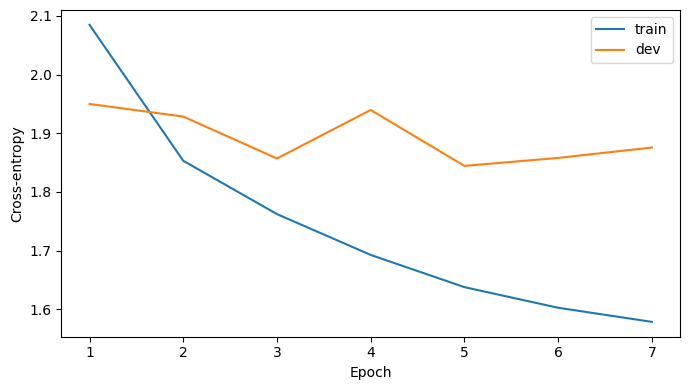

Restored /kaggle/working/phase3_rr/best_model2_full_finetuning_regularized.pt (epoch 6, Macro-F1=0.2235)
Finished recipe=regularized, official 13-class dev Macro-F1=0.2235

Full fine-tuning recipe: balanced
Trainable backbone parameters: 59665152
Class weights: {'Fact': 0.6, 'Issue': 1.33, 'ArgumentPetitioner': 0.6, 'ArgumentRespondent': 0.6, 'Statute': 0.6, 'Dissent': 0.94, 'PrecedentReliedUpon': 0.6, 'PrecedentNotReliedUpon': 0.74, 'PrecedentOverruled': 2.25, 'RulingByLowerCourt': 0.64, 'RatioOfTheDecision': 0.6, 'RulingByPresentCourt': 0.92, 'None': 0.93}
balanced: backbone top LR=8e-06; lower LR=1.56513e-06; head LR=0.00018; groups=33
epoch=1 train_loss=2.1738 dev_loss=1.9520 dev_macro_f1=0.1289 supported_f1=0.1523
epoch=2 train_loss=1.9386 dev_loss=1.8990 dev_macro_f1=0.1850 supported_f1=0.2187
epoch=3 train_loss=1.8192 dev_loss=1.8180 dev_macro_f1=0.2032 supported_f1=0.2401
epoch=4 train_loss=1.7351 dev_loss=1.8546 dev_macro_f1=0.2145 supported_f1=0.2535
epoch=5 train_loss=1.6730

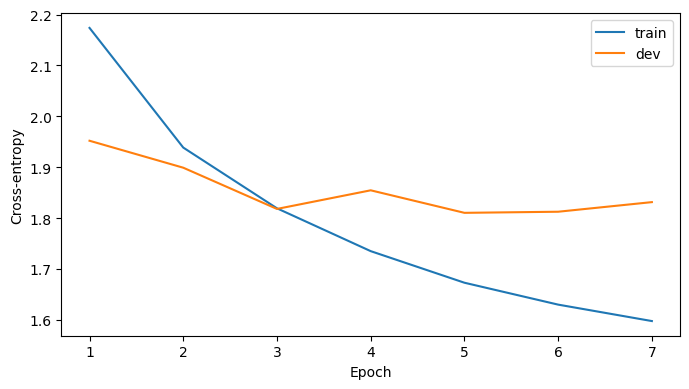

Restored /kaggle/working/phase3_rr/best_model2_full_finetuning_balanced.pt (epoch 6, Macro-F1=0.2501)
Finished recipe=balanced, official 13-class dev Macro-F1=0.2501

SUMMARY — selected by official development Macro-F1
balanced: 0.2501 at /kaggle/working/phase3_rr/best_model2_full_finetuning_balanced.pt
regularized: 0.2235 at /kaggle/working/phase3_rr/best_model2_full_finetuning_regularized.pt
Chosen: balanced | checkpoint: /kaggle/working/phase3_rr/best_model2_full_finetuning_balanced.pt


In [9]:
import gc

results = []
model = None
optimizer = None
for recipe_index, recipe in enumerate(TRAIN_RECIPES):
    assert recipe in ('regularized', 'balanced'), f'Unknown recipe {recipe}'
    print('\n' + '='*72)
    print('Full fine-tuning recipe:', recipe)
    print('='*72)
    # Free the previous recipe's optimizer & model before starting a fresh run.
    if model is not None:
        del model, optimizer
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    if recipe_index == 0:
        trial_backbone = backbone
        backbone = None
    else:
        # Reload the ORIGINAL Phase-1 state, never continue from previous trial.
        trial_backbone = CustomLegalModel(VOCAB_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)
        trial_backbone.forward_hidden = _forward_hidden.__get__(trial_backbone, CustomLegalModel)
        trial_backbone.load_state_dict(state, strict=True)
    trial_backbone.to(DEVICE)
    # Same classifier initialization and shuffle seed for a cleaner comparison.
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)
    model = SentenceClassifier(trial_backbone, N_EMBD, len(label_names)).to(DEVICE)
    total_backbone = sum(p.numel() for p in model.backbone.parameters())
    assert all(p.requires_grad for p in model.backbone.parameters()), 'Backbone must remain fully trainable'
    print('Trainable backbone parameters:', total_backbone)
    class_weights = make_class_weights(train_records, label_names, recipe)
    optimizer = make_optimizer(model, recipe)
    ckname = f'best_model2_full_finetuning_{recipe}.pt'
    model, history, best_path = train_model(
        model, train_loader, dev_loader, label_names, optimizer,
        class_weights=class_weights, checkpoint_name=ckname
    )
    metrics, _, _ = evaluate(model, dev_loader, len(label_names))
    results.append({'recipe': recipe, 'macro_f1': metrics['macro_f1'],
                    'checkpoint_path': str(best_path), 'metrics': metrics})
    print(f'Finished recipe={recipe}, official 13-class dev Macro-F1={metrics["macro_f1"]:.4f}')

if not results:
    raise RuntimeError('No recipes completed')
results = sorted(results, key=lambda row: row['macro_f1'], reverse=True)
best_trial = results[0]
# The last model has exactly the same architecture as every trial; just restore
# the best checkpoint (which may come from an earlier recipe).
best_ck = torch.load(best_trial['checkpoint_path'], map_location='cpu', weights_only=False)
model.load_state_dict(best_ck['model_state_dict'])
model.eval()
best_path = Path(best_trial['checkpoint_path'])
print('\nSUMMARY — selected by official development Macro-F1')
for res in results:
    print(f"{res['recipe']}: {res['macro_f1']:.4f} at {res['checkpoint_path']}")
print('Chosen:', best_trial['recipe'], '| checkpoint:', best_path)
with open(OUTPUT_DIR/'experiment_results.json', 'w') as f:
    json.dump(results, f, indent=2)


The cell above runs both full-fine-tuning recipes from the same Phase-1 checkpoint, restores the winner, and saves their individual histories and checkpoints. The checkpoint is chosen by official 13-class Macro-F1, not training accuracy.


Development metrics: {
  "loss": 1.8125003160757511,
  "macro_f1": 0.25014913506584374,
  "macro_precision": 0.29698863971640477,
  "macro_recall": 0.24743467270019803,
  "supported_macro_f1_diagnostic": 0.2956307959869062
}
                        precision    recall  f1-score   support

                  Fact       0.49      0.68      0.57       444
                 Issue       0.00      0.00      0.00        15
    ArgumentPetitioner       0.46      0.25      0.33       400
    ArgumentRespondent       0.40      0.15      0.21       272
               Statute       0.75      0.64      0.69       120
               Dissent       0.00      0.00      0.00         0
   PrecedentReliedUpon       0.33      0.27      0.30       254
PrecedentNotReliedUpon       0.33      0.10      0.15        50
    PrecedentOverruled       0.00      0.00      0.00         0
    RulingByLowerCourt       0.12      0.01      0.02       102
    RatioOfTheDecision       0.31      0.62      0.41       403
  Ruli

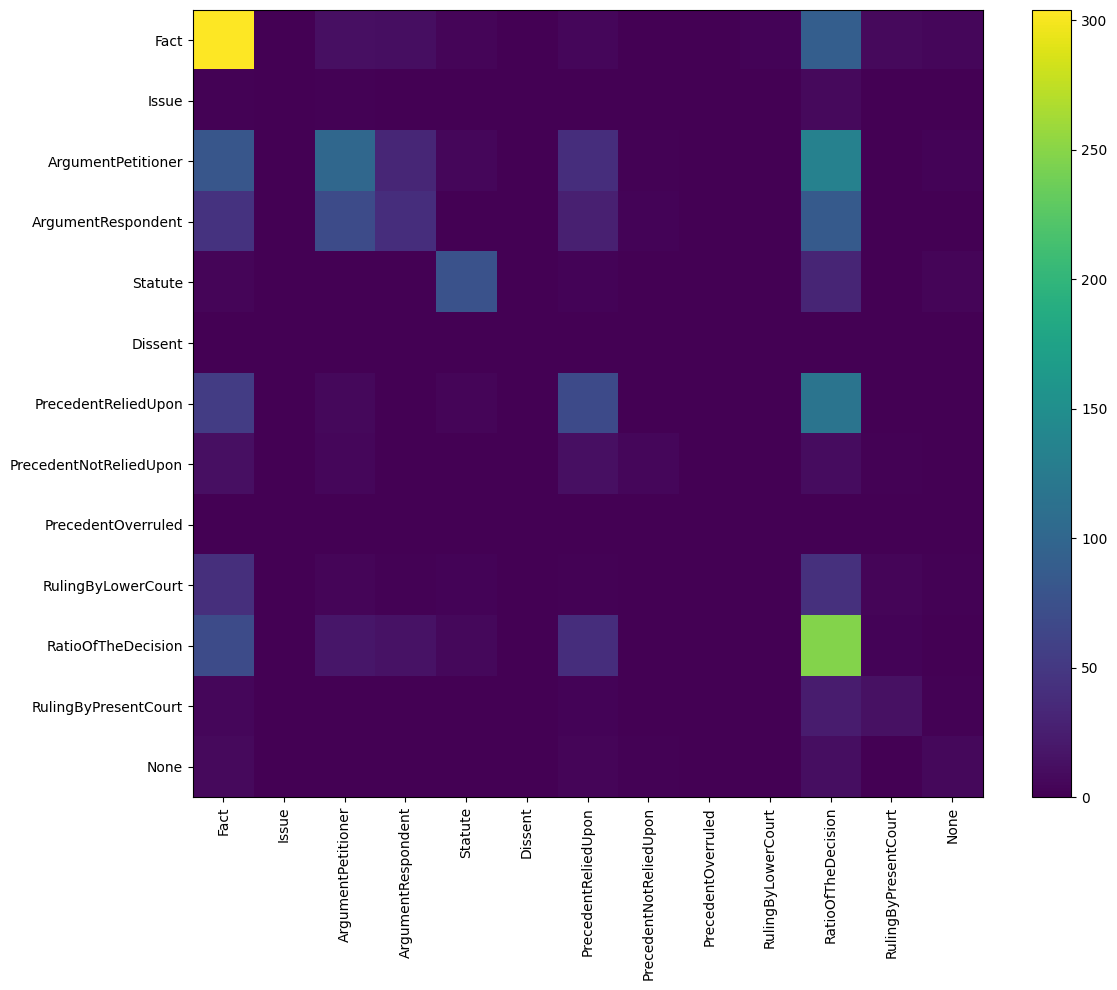

CL development metrics: {
  "loss": 1.7999926376287267,
  "macro_f1": 0.24153994510442267,
  "macro_precision": 0.2854799605823616,
  "macro_recall": 0.2737273383290045,
  "supported_macro_f1_diagnostic": 0.3140019286357495
}
IT development metrics: {
  "loss": 1.8359061057701827,
  "macro_f1": 0.23557016105059206,
  "macro_precision": 0.2867830586562055,
  "macro_recall": 0.2353344666026724,
  "supported_macro_f1_diagnostic": 0.278401099423427
}


In [10]:
metrics, gold, pred = evaluate(model, dev_loader, len(label_names))
print('Development metrics:', json.dumps(metrics, indent=2))
print(classification_report(gold, pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))
with open(OUTPUT_DIR / 'dev_report.txt', 'w', encoding='utf-8') as f:
    f.write(classification_report(gold, pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))
cm = confusion_matrix(gold, pred, labels=list(range(len(label_names))))
plt.figure(figsize=(12, 10))
plt.imshow(cm, aspect='auto')
plt.xticks(range(len(label_names)), label_names, rotation=90)
plt.yticks(range(len(label_names)), label_names)
plt.colorbar()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'dev_confusion_matrix.png', dpi=150)
plt.show()


# Domain-specific diagnostics (checkpoint selection still uses the combined dev set).
for domain_name, domain_rows in [('CL', data['CL_dev']), ('IT', data['IT_dev'])]:
    domain_records = records_from_payload(domain_rows, True)
    for r in domain_records:
        r['domain'] = domain_name
    domain_loader = DataLoader(RRDataset(domain_records, tokenizer, label_to_id, True), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_rr)
    domain_metrics, domain_gold, domain_pred = evaluate(model, domain_loader, len(label_names))
    print(f'{domain_name} development metrics:', json.dumps(domain_metrics, indent=2))
    with open(OUTPUT_DIR / f'{domain_name.lower()}_dev_report.txt', 'w', encoding='utf-8') as f:
        f.write(classification_report(domain_gold, domain_pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))


## 6. Document-held-out calibration and training-only sequence prior

Class-bias adjustment is considered only when a separate development-document holdout improves. In addition, an order-based transition prior learned exclusively from training labels can smooth rhetorical-role sequences; its strength is likewise selected using document-held-out checks. Both affect inference only.


In [11]:
# Optional small per-class bias calibration (does not fine-tune on dev labels).
# Split dev by DOCUMENT to prevent sentence-level leakage across calibration and check folds.
# The independent check portion decides whether bias calibration is used.
from sklearn.model_selection import GroupShuffleSplit
selected_bias = np.zeros(len(label_names), dtype=np.float32)
raw_metrics, calib_gold, _, dev_logits = evaluate(model, dev_loader, len(label_names), return_logits=True)
print('Best checkpoint RAW dev Macro-F1:', raw_metrics['macro_f1'])

if ENABLE_BIAS_CALIBRATION:
    groups = np.asarray([r['domain'] + ':' + r['doc_id'] for r in dev_records])
    indices = np.arange(len(groups))
    if len(set(groups)) >= 5:
        split = GroupShuffleSplit(n_splits=1, train_size=0.6, random_state=BIAS_CALIBRATION_SEED)
        fit_idx, check_idx = next(split.split(indices, calib_gold, groups))
        y = np.asarray(calib_gold, dtype=np.int64)
        classes = list(range(len(label_names)))
        supported = set(y[fit_idx].tolist())
        bias = np.zeros(len(label_names), dtype=np.float32)
        def _f1(idx, candidate):
            return f1_score(y[idx], (dev_logits[idx] + candidate).argmax(axis=1),
                            labels=classes, average='macro', zero_division=0)
        best_fit = _f1(fit_idx, bias)
        # Coordinate search is deliberately bounded and excludes labels with no calibration support.
        for _ in range(2):
            improved = False
            for cls in range(len(label_names)):
                if cls not in supported or int((y[fit_idx] == cls).sum()) < 8:
                    continue
                chosen = bias[cls]
                for delta in (-0.40, -0.20, 0.20, 0.40):
                    cand = bias.copy()
                    cand[cls] = np.clip(cand[cls] + delta, -0.80, 0.80)
                    score = _f1(fit_idx, cand)
                    if score > best_fit + 0.0003:
                        best_fit, chosen = score, cand[cls]
                        improved = True
                bias[cls] = chosen
            if not improved:
                break
        raw_check = _f1(check_idx, np.zeros_like(bias))
        calibrated_check = _f1(check_idx, bias)
        print(f'Bias calibration document-holdout: raw={raw_check:.4f}; calibrated={calibrated_check:.4f}')
        if calibrated_check > raw_check + 0.005:
            selected_bias = bias
            print('Bias calibration accepted based on independent dev-document check.')
        else:
            print('Bias calibration rejected; keeping raw logits.')
    else:
        print('Insufficient dev documents for document-held-out calibration; skipping.')

np.save(OUTPUT_DIR/'selected_logit_bias.npy', selected_bias)
final_metrics, _, _ = evaluate(model, dev_loader, len(label_names), bias=selected_bias)
print('Full-dev official Macro-F1 after selected postprocessing:', final_metrics['macro_f1'])
print('NOTE: this is DEVELOPMENT-set tuning, not independent test performance.')

# Order-aware decoding. Transition priors use TRAIN labels only; strengths are
# fitted/checked on two disjoint groups of development documents.
transition_prior = fit_train_transition_prior(train_records, label_to_id)
selected_transition_strength = 0.0
groups = np.asarray([r['domain'] + ':' + r['doc_id'] for r in dev_records])
if len(set(groups)) >= 5:
    train_ix, heldout_ix = next(GroupShuffleSplit(
        n_splits=1, train_size=0.6, random_state=BIAS_CALIBRATION_SEED
    ).split(np.arange(len(groups)),calib_gold,groups))
    calibrated_logits = dev_logits + selected_bias[None,:]
    y_true = np.asarray(calib_gold)
    scores = {}
    for strength in (0.0,0.15,0.30,0.50,0.80):
        sequence_pred = structured_decode(calibrated_logits,dev_records,transition_prior,strength)
        fit_f1 = f1_score(y_true[train_ix],sequence_pred[train_ix],average='macro',
                          labels=list(range(len(label_names))),zero_division=0)
        check_f1 = f1_score(y_true[heldout_ix],sequence_pred[heldout_ix],average='macro',
                            labels=list(range(len(label_names))),zero_division=0)
        scores[strength] = (fit_f1,check_f1)
    trial_strength = max(scores,key=lambda x:scores[x][0])
    if trial_strength > 0 and scores[trial_strength][1] > scores[0.0][1] + 0.005:
        selected_transition_strength = trial_strength
    print('Order-decoding calibration:',scores)
    print('Selected transition strength:',selected_transition_strength)
else:
    print('Skipping order-decoding validation: too few distinct dev documents.')

ordered_yhat = structured_decode(dev_logits+selected_bias[None,:],dev_records,
                                 transition_prior,selected_transition_strength)
raw_full_yhat = dev_logits.argmax(axis=-1)
ordered_f1 = f1_score(calib_gold,ordered_yhat,labels=list(range(len(label_names))),
                      average='macro',zero_division=0)
print(f'Final raw model Macro-F1={raw_metrics["macro_f1"]:.4f}; '
      f'final dev postprocessed Macro-F1={ordered_f1:.4f}')
with open(OUTPUT_DIR/'postprocessing_choice.json','w') as f:
    json.dump({'selected_bias':selected_bias.tolist(),
               'selected_transition_strength':selected_transition_strength,
               'raw_macro_f1':raw_metrics['macro_f1'],
               'postprocessed_dev_macro_f1':ordered_f1},f,indent=2)


Best checkpoint RAW dev Macro-F1: 0.25014913506584374
Bias calibration document-holdout: raw=0.2329; calibrated=0.2261
Bias calibration rejected; keeping raw logits.
Full-dev official Macro-F1 after selected postprocessing: 0.25014913506584374
NOTE: this is DEVELOPMENT-set tuning, not independent test performance.
Order-decoding calibration: {0.0: (0.24686878221698863, 0.2329169361605952), 0.15: (0.2481068046233001, 0.2325679649066288), 0.3: (0.26040986957207934, 0.2573784386124813), 0.5: (0.2536466435928353, 0.25083780380592935), 0.8: (0.27480895743358325, 0.25837351944134324)}
Selected transition strength: 0.8
Final raw model Macro-F1=0.2501; final dev postprocessed Macro-F1=0.2770


## 6. Generate test prediction JSON

Output maps each document ID to ordered official label strings, one per sentence.

In [12]:
# Save per-domain predictions first, so overlapping CL/IT document IDs are safe.
for domain in keys:
    subset = [r for r in test_records if r['domain'] == domain]
    path = save_predictions(model,subset,label_names,label_to_id,
                            f'model2_fft_{domain.lower()}',
                            bias=selected_bias,transition_prior=transition_prior,
                            transition_strength=selected_transition_strength)
    print(domain,'prediction JSON:',path)

ids_to_domains={}
collision=False
for r in test_records:
    if r['doc_id'] in ids_to_domains and ids_to_domains[r['doc_id']] != r['domain']:
        collision=True
    ids_to_domains[r['doc_id']]=r['domain']
if collision:
    print('WARNING: CL and IT have overlapping document IDs. Use the individual domain JSON files.')
else:
    pred_path = save_predictions(model,test_records,label_names,label_to_id,
                                 'model2_full_finetuning',bias=selected_bias,
                                 transition_prior=transition_prior,
                                 transition_strength=selected_transition_strength)
    print('Combined prediction JSON:',pred_path)


CL prediction JSON: /kaggle/working/phase3_rr/model2_fft_cl_prediction.json
IT prediction JSON: /kaggle/working/phase3_rr/model2_fft_it_prediction.json
Combined prediction JSON: /kaggle/working/phase3_rr/model2_full_finetuning_prediction.json


## Experiment integrity & limitations

- **Same Phase-1 model and tokenizer:** exact pretrained parameters loaded with `strict=True`, no external pretrained model.
- **Full fine-tuning:** all Model 2 backbone parameters receive optimizer updates; lower layers receive smaller learning rates, not frozen.
- **Data:** `CL_train` / `IT_train` labels only for loss/weights; development labels for model selection and optional document-held-out bias calibration. No test labels.
- **Metric:** official Macro-F1 over all 13 label IDs; supported-only Macro-F1 is diagnostic and not the official target. Two dev-absent labels impose a ceiling but are not omitted.
- **Speed/memory:** batch 4, gradient accumulation 2, AMP on CUDA, activation checkpointing. Two full runs may take considerable Kaggle time. Set `TRAIN_RECIPES=("regularized",)` to run one.
- **Comparability:** architecture/readout/context/loss are changed from LoRA; this is a performance-oriented variant, **not** a clean controlled comparison of adaptation algorithms.
- **Accuracy:** syntax and synthetic smoke tests do not establish 0.5 Macro-F1. Verify real scores on your development data.
- **Sequence prior:** learned only from training sentence labels. Strength is selected from candidate values on document-separated portions of development; never trained on test labels.
